In [230]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [231]:
pd.set_option("display.max_columns", None)

In [232]:
sns.set_style("whitegrid")

In [233]:
df = pd.read_csv('/Users/otistran/Documents/german_credit_data 2.csv')

# Data Cleaning 

In [235]:
df.head()

,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,2,49,male,1,own,little,NaN,2096,12,education,good
3,3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,4,53,male,2,free,little,little,4870,24,car,bad


In [236]:
df["Age"].describe()

count    1000.000000
mean       35.546000
std        11.375469
min        19.000000
25%        27.000000
50%        33.000000
75%        42.000000
max        75.000000
Name: Age, dtype: float64

In [237]:
df["Risk"].value_counts()

Risk
good    700
bad     300
Name: count, dtype: int64

In [238]:
df.shape

(1000, 11)

In [239]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Unnamed: 0        1000 non-null   int64 
 1   Age               1000 non-null   int64 
 2   Sex               1000 non-null   object
 3   Job               1000 non-null   int64 
 4   Housing           1000 non-null   object
 5   Saving accounts   817 non-null    object
 6   Checking account  606 non-null    object
 7   Credit amount     1000 non-null   int64 
 8   Duration          1000 non-null   int64 
 9   Purpose           1000 non-null   object
 10  Risk              1000 non-null   object
dtypes: int64(5), object(6)
memory usage: 86.1+ KB


In [240]:
df["Job"].unique()

array([2, 1, 3, 0])

In [241]:
df.isna().sum()

Unnamed: 0            0
Age                   0
Sex                   0
Job                   0
Housing               0
Saving accounts     183
Checking account    394
Credit amount         0
Duration              0
Purpose               0
Risk                  0
dtype: int64

In [242]:
df.duplicated().sum()

0

In [243]:
df = df.dropna().reset_index(drop = True)

In [244]:
df.columns

Index(['Unnamed: 0', 'Age', 'Sex', 'Job', 'Housing', 'Saving accounts',
       'Checking account', 'Credit amount', 'Duration', 'Purpose', 'Risk'],
      dtype='object')

In [245]:
df.drop(columns = "Unnamed: 0", inplace = True)

In [246]:
df

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,22,female,2,own,little,moderate,5951,48,radio/TV,bad
1,45,male,2,free,little,little,7882,42,furniture/equipment,good
2,53,male,2,free,little,little,4870,24,car,bad
3,35,male,3,rent,little,moderate,6948,36,car,good
4,28,male,3,own,little,moderate,5234,30,car,bad
...,...,...,...,...,...,...,...,...,...,...
517,48,male,1,own,little,moderate,1743,24,radio/TV,good
518,30,male,3,own,little,little,3959,36,furniture/equipment,good
519,40,male,3,own,little,little,3857,30,car,good
520,23,male,2,free,little,little,1845,45,radio/TV,bad


# Explorary Data Analysis

Text(0.5, 0.98, 'Distribution of Numeric Features')

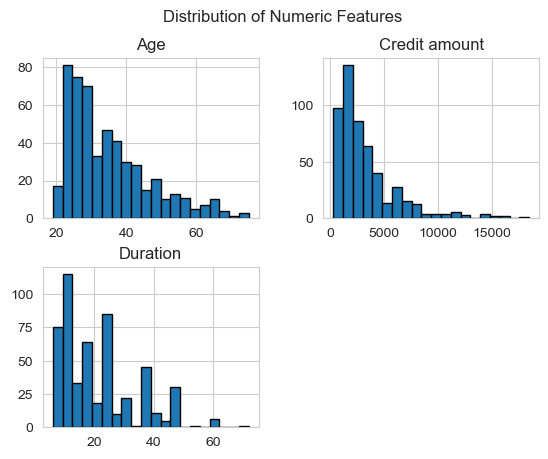

In [248]:
df[["Age", "Credit amount", "Duration"]].hist(bins = 20, edgecolor = "black")
plt.suptitle("Distribution of Numeric Features")

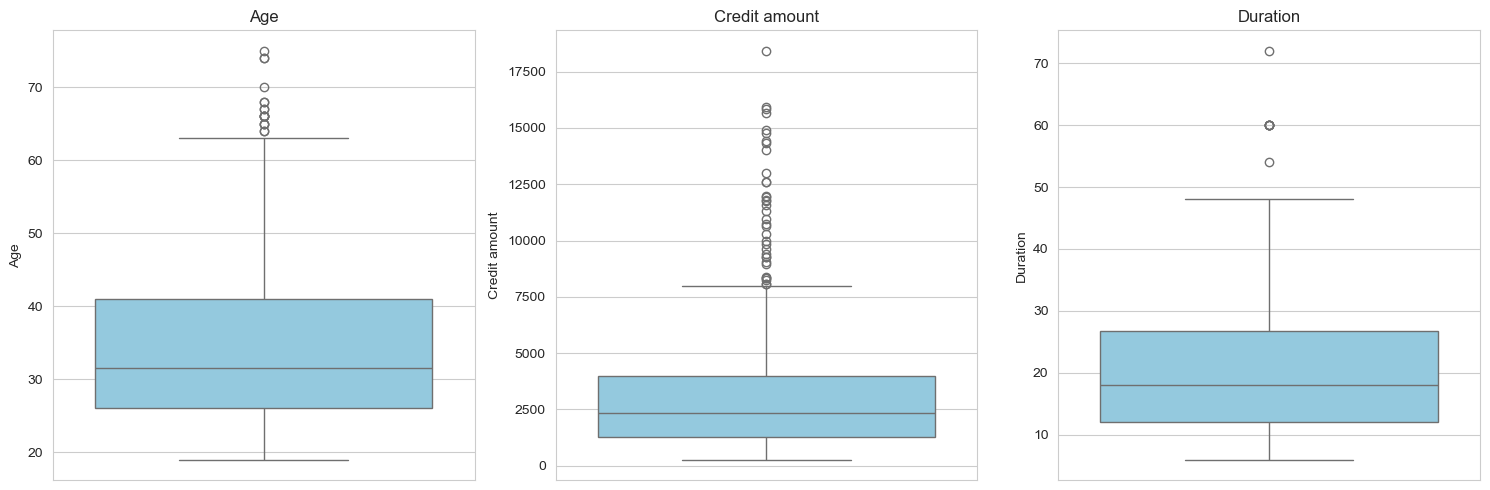

In [249]:
plt.figure(figsize = (15,5))
for i, col in enumerate (["Age", "Credit amount", "Duration"]):
    plt.subplot(1,3,i+1)
    sns.boxplot(y = df[col], color = "skyblue")
    plt.title(col)
plt.tight_layout()
plt.show()

### First Touch Business Insights 
#### 1. Right skewed Distribution
- The majority of loan applicants are young and middle aged individuals (under 42), who typically have the highest demand for consumer credit, mortgages and installment loans.
- Older customers (above 60 - 75) represent a very small proportion and are treated as statistical outliers
#### 2.Age Based Risk Segmentation 
- Age 19 - 26 (Young segment): Requires careful evaluation of credit scores and repayment history, as this group is typically starting their careers and may have less stable incomes.
- Age 27 - 42 (Core Segment): This group forms the majority, with income entering a stable and growing phase. They are the target demographic for optimizing automated credit approval workflows.
- Age > 64 (Outlier segment): Small in number but carries distict risk profiles (pension based income, health risks). Policies regarding collateral or maximum loan tenors should be carefully tailored to their age bracket

In [251]:
categorical_cols = ["Sex", "Job", "Housing", "Saving accounts", "Checking account", "Purpose"]

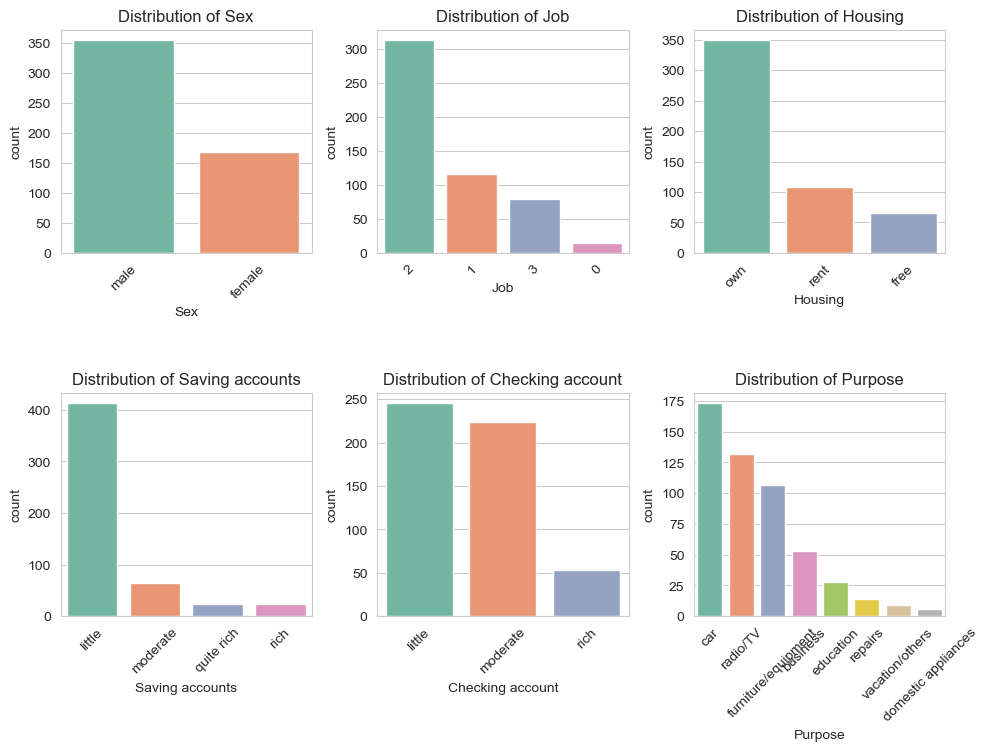

In [252]:
plt.figure(figsize = (10,10))
for i, col in enumerate(categorical_cols):
    plt.subplot(3,3,i+1)
    sns.countplot(data = df, x = col, palette = "Set2", order = df[col].value_counts().index)
    plt.title(f"Distribution of {col}")
    plt.xticks(rotation = 45)
plt.tight_layout()
plt.show()

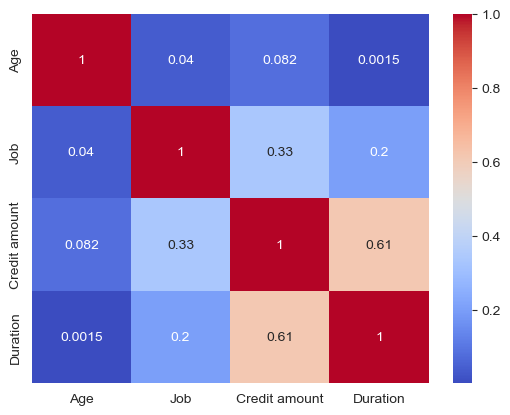

In [253]:
corr = df[["Age", "Job", "Credit amount", "Duration"]].corr()
sns.heatmap(corr, annot = True, cmap = "coolwarm")
plt.show()

In [254]:
df.groupby("Job")["Credit amount"].mean()

Job
0    1767.857143
1    2250.715517
2    3129.130990
3    5648.784810
Name: Credit amount, dtype: float64

In [255]:
df.groupby("Sex")["Credit amount"].mean()

Sex
female    2937.202381
male      3440.833333
Name: Credit amount, dtype: float64

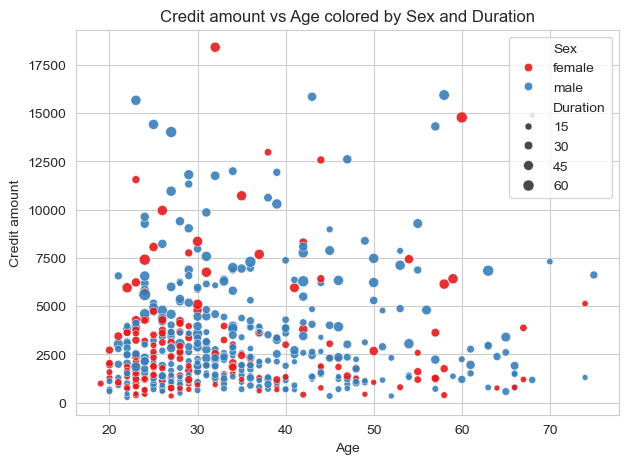

In [256]:
plt.figure(figsize = (7,5))
sns.scatterplot(data = df, x = "Age", y = "Credit amount", hue = "Sex", size = "Duration", alpha = 0.9, palette = "Set1")
plt.title("Credit amount vs Age colored by Sex and Duration")
plt.show()

### Insignts
#### 1.Age and Credit Amount Distribution: 
- High value loans (above 10,000 up to nearly 17,500) are primarily concentrated in the 20 - 50 age range.
- Older borrowers (above 60 years old) generally request smaller to moderate credit amounts, rarely taking on large loans.
#### 2. Impact of Loan Duration
- Larger buble sizes (representing long term durations like 45 - 60 months) tend to cluster around higher credit ammount, which aligns with standard credit risk logic(larger loans require longer repayment periods)
#### 3. Gender Profile Differences:
- Male applicants(Red): Dominate the overall dataset across almost all age brackets and credit amounts
- Female applicants(Blue): Are concentrated mostly in younger are groups (under 40) and generally take lower moderate loan amounts.

<Axes: xlabel='Saving accounts', ylabel='Credit amount'>

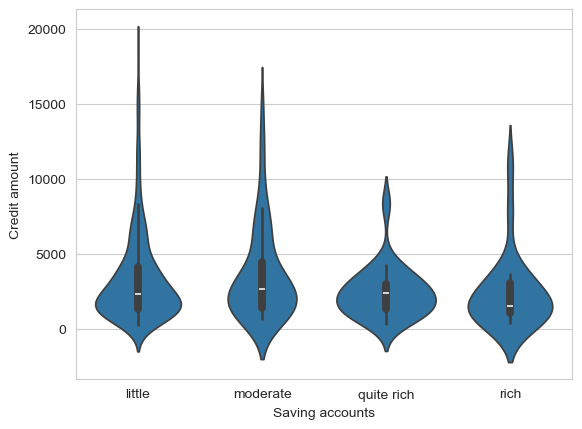

In [258]:
sns.violinplot(data = df, x = "Saving accounts", y = "Credit amount")

### Insights
#### 1.Consistent Core Demand Across All Groups
- The wide belly of the violin for all four groups is concentrated between 1,000 and 4,000.
- The median credit amount around 2,500 across all saving tiers. This indicates that rountine credit demand is baseline driven rather than savings driven.
#### 2. High Risk Rail in Low Savings
- The little saving groups show the longest upper tail, extending up to 20,000
- Risk Insight: Borrowers with low savings taking out maximum tier loans represent the highest default risk segment. Credit policies should require stricter income verification or collateral for this specific subset.
#### 3. Moderate and Wealthier Tigers
- The upper tails are more bounded compared to little group
- The moderate group retains a secondary long tail up to around 17,000 while the rich and quite rich groups show more capped distributions

In [260]:
df["Risk"].value_counts(normalize = True)

Risk
good    0.557471
bad     0.442529
Name: proportion, dtype: float64

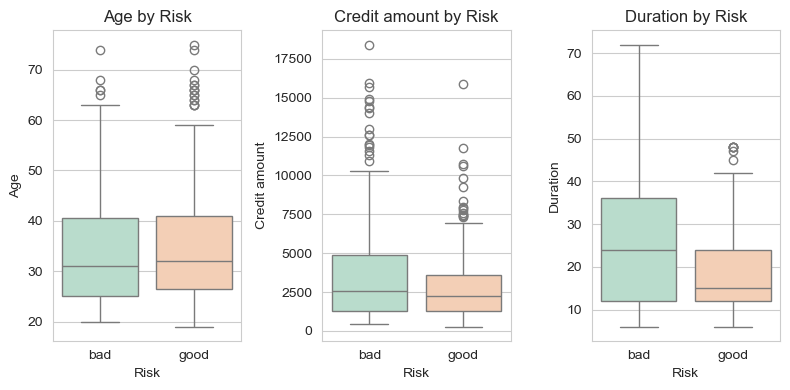

In [261]:
plt.figure(figsize = (8,4))
for i, col in enumerate(["Age", "Credit amount", "Duration"]):
    plt.subplot(1,3,i+1)
    sns.boxplot(data = df, x = "Risk", y = col, palette = "Pastel2")
    plt.title(f"{col} by Risk")
plt.tight_layout()
plt.show()

In [262]:
df.groupby("Risk")[["Age", "Credit amount", "Duration"]].mean()

,Age,Credit amount,Duration
Risk,,,
bad,34.147186,3881.090909,25.445887
good,35.477663,2800.594502,18.079038


In [263]:
categorical_cols

['Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account', 'Purpose']

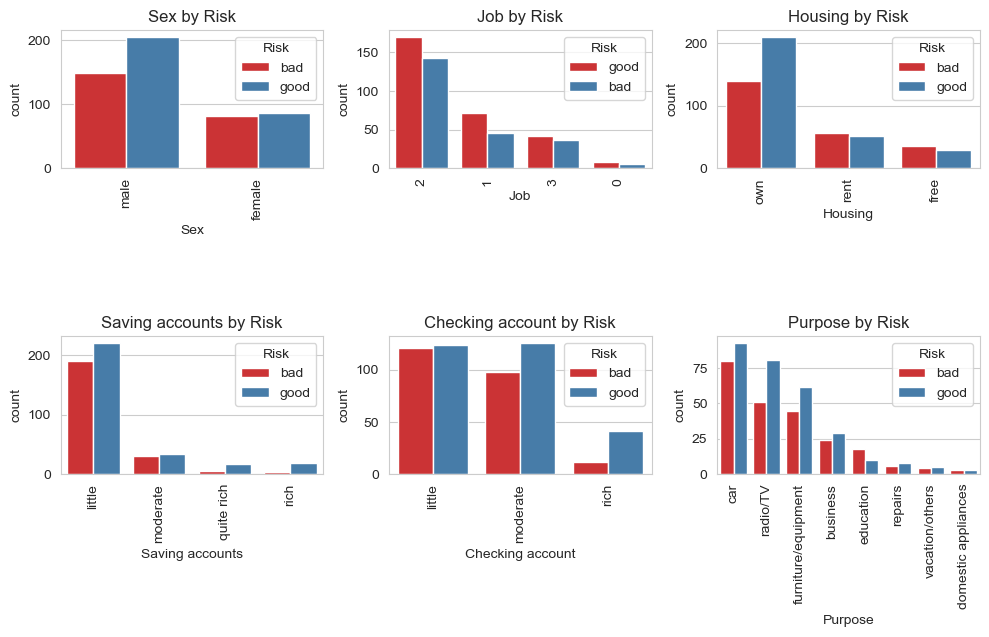

In [264]:
plt.figure(figsize = (10,8))
for i, col in enumerate(categorical_cols):
    plt.subplot(3,3,i+1)
    sns.countplot(data = df, x = col, hue = "Risk", palette = "Set1", order = df[col].value_counts().index)
    plt.title(f"{col} by Risk")
    plt.xticks(rotation = 90)
plt.tight_layout()
plt.show()

# Feature Engineering

In [266]:
df.columns

Index(['Age', 'Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account',
       'Credit amount', 'Duration', 'Purpose', 'Risk'],
      dtype='object')

In [267]:
features = ["Age", "Sex", "Job", "Housing", "Saving accounts", "Checking account", "Credit amount", "Duration"]
target = "Risk"

In [268]:
df_model = df[features + [target]].copy()

In [269]:
df_model

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Risk
0,22,female,2,own,little,moderate,5951,48,bad
1,45,male,2,free,little,little,7882,42,good
2,53,male,2,free,little,little,4870,24,bad
3,35,male,3,rent,little,moderate,6948,36,good
4,28,male,3,own,little,moderate,5234,30,bad
...,...,...,...,...,...,...,...,...,...
517,48,male,1,own,little,moderate,1743,24,good
518,30,male,3,own,little,little,3959,36,good
519,40,male,3,own,little,little,3857,30,good
520,23,male,2,free,little,little,1845,45,bad


In [270]:
from sklearn.preprocessing import LabelEncoder
import joblib

In [271]:
cat_cols = df_model.select_dtypes(include = "object").columns.drop("Risk")
le_dict = {}
cat_cols

Index(['Sex', 'Housing', 'Saving accounts', 'Checking account'], dtype='object')

In [272]:
for col in cat_cols:
    le = LabelEncoder()
    df_model[col] = le.fit_transform(df_model[col])
    le_dict[col] = le
    joblib.dump(le, f"{col}_encoder.pkl")

In [273]:
le_target = LabelEncoder()

In [274]:
df_model[target] = le_target.fit_transform(df_model[target])

In [275]:
df_model[target].value_counts()

Risk
1    291
0    231
Name: count, dtype: int64

In [317]:
df_model.head()

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Risk
0,22,0,2,1,0,1,5951,48,0
1,45,1,2,0,0,0,7882,42,1
2,53,1,2,0,0,0,4870,24,0
3,35,1,3,2,0,1,6948,36,1
4,28,1,3,1,0,1,5234,30,0


# Train Test Split

In [319]:
from sklearn.model_selection import train_test_split

In [322]:
X = df_model.drop(target, axis = 1)
y = df_model[target]

In [332]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, stratify = y, random_state = 1)

# Build Model

In [347]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier 
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV

In [362]:
def train_model(model, param_grid, X_train, y_train, X_test, y_test):
    grid = GridSearchCV(model, param_grid, cv = 5, scoring = "accuracy", n_jobs = -1)
    grid.fit(X_train, y_train)
    best_model = grid.best_estimator_
    y_pred = best_model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    return best_model, acc, grid.best_params_

### Decision Tree

In [364]:
dt = DecisionTreeClassifier(random_state = 1, class_weight = "balanced")
dt_param_grid = {
    "max_depth": [3,5,7,10, None],
    "min_samples_split": [2,5,10],
    "min_samples_leaf": [1,3,4]
}

In [366]:
best_dt,acc_dt, params_dt = train_model(dt, dt_param_grid, X_train, y_train, X_test, y_test)

In [368]:
print("Discision Tree Accuracy",acc_dt)

Discision Tree Accuracy 0.580952380952381


In [370]:
print("Best parameters", params_dt)

Best parameters {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2}


### Random Forest 

In [374]:
rf = RandomForestClassifier(random_state = 1, class_weight = "balanced", n_jobs = -1)

In [401]:
rf_param_grid = {
    "n_estimators": [100,200],
    "max_depth": [5,7,10,None],
    "min_samples_split": [2,5,10],
    "min_samples_leaf": [1,2,4]
}

In [403]:
best_rf, acc_rf, params_rf = train_model(rf, rf_param_grid, X_train, y_train, X_test, y_test)

In [406]:
print("Random Forest Accuracy", acc_rf)

Random Forest Accuracy 0.6190476190476191


In [405]:
print("Best parameters", params_rf)

Best parameters {'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 10, 'n_estimators': 100}


### ExtraTree

In [410]:
et = ExtraTreesClassifier(random_state = 1, class_weight = "balanced", n_jobs = -1)

In [412]:
et_param_grid = {
    "n_estimators": [100,200],
    "max_depth": [5,7,10,None],
    "min_samples_split": [2,5,10],
    "min_samples_leaf": [1,2,4]
}

In [414]:
best_et, acc_et, params_et = train_model(et,et_param_grid, X_train, y_train, X_test, y_test)

In [415]:
print("Random Forest Accuracy", acc_et)

Random Forest Accuracy 0.6666666666666666


In [418]:
best_et.predict(X_test)

array([1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1,
       1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1,
       1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1,
       0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1,
       0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1])